# Calorimeter edges and vertex outliers

Explore particle-level cuts on the output of `macros/edge_outlier_study.C`, which writes one entry per reco
particle **before any cut**:
```
root -l -b -q 'macros/edge_outlier_study.C("<file or dir/*.hipo>","plots/edge_outlier_study/study.root",-1)'
```
* `pass_prod`: kept by the production cuts (`CutManager::filter_particles`).
* `pass_loose`: kept by the production cuts with **chi2pid, the v_z / v_T outlier cuts and the e⁻ / γ
  calorimeter edge cuts switched off**. Use it as the baseline when the cut under study is one of those.
* `pass_nobeta`: kept by the production cuts with **the e± / γ β outlier cut (0 < β < 2) switched off**.
* `pcal_*`, `ecin_*`, `ecout_*`: energy `_e`, hit position `_x/_y/_z` (cm) and edge distances `_lv/_lw` per
  calorimeter layer; all 0 in a layer with no hit.
* `truepid`, `truep`, `trueE`: the MC particle closest in angle, ΔR = √((Δθ/2°)² + (Δφ/4°)²) < 1
  (`CLAS12Ana::match_mc_to_reco`), −999 when unmatched and on real data.

Production values for reference: v_z ∈ (−40, 30) cm, v_T = √(v_x² + v_y²) < 20 cm, |χ²_pid| < 3 (pions:
momentum dependent), calorimeter edge min(lv, lw) ≥ 9 cm (e⁻) / 14 cm (γ) in PCAL and none for hadrons,
0 < β < 2 for e± and γ.

Each plot cell is a config block and one `overlay(...)` call. To try another cut, edit its selections dict.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import uproot
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.ticker import PercentFormatter

FILE = "plots/edge_outlier_study/clasdis-0001.root"

df = uproot.open(FILE)["particles"].arrays(library="pd")
print(f"{len(df):,} reco particles   pass_loose {df.pass_loose.mean():.1%}   pass_prod {df.pass_prod.mean():.1%}   "
      f"matched to truth {(df.truepid != -999).mean():.1%}")

In [ ]:
# dataviz reference palette: categorical slots in fixed order, blue sequential ramp, chart surface and ink
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQUENTIAL = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({"axes.facecolor": "#fcfcfb", "figure.facecolor": "#fcfcfb", "text.color": "#0b0b0b",
                     "axes.labelcolor": "#0b0b0b", "axes.edgecolor": "#c3c2b7", "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "font.size": 9})
PID_NAMES = {11: "e⁻", -11: "e⁺", 13: "μ⁻", -13: "μ⁺", 22: "γ", 111: "π⁰", 211: "π⁺", -211: "π⁻", 321: "K⁺",
             -321: "K⁻", 130: "K⁰L", 2212: "p", -2212: "p̄", 2112: "n", -2112: "n̄"}


def calo(d, var, layer="pcal"):
    """Calorimeter quantity `var` ('x', 'y', 'z', 'lv', 'lw', 'e') in layer 'pcal', 'ecin' or 'ecout'; NaN where
    that layer has no energy. 'first' takes the innermost layer that was hit."""
    if layer == "first":
        return calo(d, var, "pcal").fillna(calo(d, var, "ecin")).fillna(calo(d, var, "ecout"))
    return d[f"{layer}_{var}"].where(d[f"{layer}_e"] > 0)


def calo_edge(d, layer="pcal"):
    """Distance (cm) to the nearest calorimeter edge, min(lv, lw) as in CutManager::caloEdges."""
    return np.minimum(calo(d, "lv", layer), calo(d, "lw", layer))


def vz_window(d, lo, hi):
    return (d.vz > lo) & (d.vz < hi)


def vt_max(d, r):
    return np.hypot(d.vx, d.vy) < r


def beta_window(d, lo, hi):
    return (d.beta > lo) & (d.beta < hi)


def width68(x):
    """Half the central 68% interval: a resolution width that ignores the tails."""
    if len(x) == 0:
        return np.nan
    lo, hi = np.percentile(x, [16, 84])
    return (hi - lo) / 2


def overlay(values, selections, bins, xlabel, density=False, logy=False):
    """One step histogram of `values` per named boolean mask (None = all), with N, mean and σ68 in the legend."""
    assert len(selections) <= len(COLORS), "too many selections for one plot: split them"
    fig, ax = plt.subplots(figsize=(12, 4.5), constrained_layout=True)
    for color, (label, sel) in zip(COLORS, selections.items()):
        v = values if sel is None else values[sel]
        ax.hist(v, bins=bins, histtype="step", lw=2, color=color, density=density,
                label=f"{label}   N={len(v):,}  mean={v.mean():.3g}  σ68={width68(v):.3g}")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("normalized" if density else "particles")
    if logy:
        ax.set_yscale("log")
    ax.grid(color="#e1e0d9", lw=0.5)
    ax.set_axisbelow(True)
    ax.legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
    plt.show()


def hit_map(d, selections, layer="pcal", bins=150, ncols=2):
    """Calorimeter hit position (x, y) in `layer`, one panel per named boolean mask (None = all), each with its own
    log color scale. Particles with no hit in that layer are left out; the panel title gives how many are shown."""
    x, y = calo(d, "x", layer), calo(d, "y", layer)
    hit = x.notna() & y.notna()
    assert hit.any(), f"no particle has a {layer} hit"
    lim = 1.02 * max(x[hit].abs().max(), y[hit].abs().max())
    nrows = -(-len(selections) // ncols)
    fig, axs = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 4.4 * nrows), sharex=True, sharey=True,
                            squeeze=False, constrained_layout=True)
    for ax, (label, sel) in zip(axs.flat, selections.items()):
        m = hit if sel is None else hit & sel
        ax.set_title(f"{label}   ({m.sum():,} hits)")
        ax.set_aspect("equal")
        if m.any():
            *_, im = ax.hist2d(x[m], y[m], bins=bins, range=[[-lim, lim], [-lim, lim]], cmap=SEQUENTIAL,
                               norm=LogNorm(), cmin=1)
            fig.colorbar(im, ax=ax, label="particles / bin")
    for ax in axs.flat[len(selections):]:
        ax.set_visible(False)
    fig.supxlabel(f"{layer} hit x (cm)")
    fig.supylabel(f"{layer} hit y (cm)")
    plt.show()


def misid_bars(d, selections, top=6, logy=False):
    """MisID rate per true species: for each named boolean mask (None = all), the fraction of the particles in `d`
    whose matched truth is that species instead of their reco pid, with binomial error bars. The `top` most common
    wrong species in `d` get their own bar group, the rest are summed into 'other'. The legend gives the total."""
    assert len(selections) <= len(COLORS), "too many selections for one plot: split them"
    order = d.truepid[d.truepid != d.pid].value_counts().index
    groups = [[s] for s in order[:top]] + ([list(order[top:])] if len(order) > top else [])
    names = [f"true {PID_NAMES.get(s, s)}" for s in order[:top]] + ["other"] * (len(order) > top)
    x, width = np.arange(len(groups)), 0.8 / len(selections)
    fig, ax = plt.subplots(figsize=(12, 4.5), constrained_layout=True)
    for i, (color, (label, sel)) in enumerate(zip(COLORS, selections.items())):
        m = d if sel is None else d[sel]
        wrong = m.truepid != m.pid
        n = max(len(m), 1)
        rate = np.array([(wrong & m.truepid.isin(g)).sum() for g in groups]) / n
        ax.bar(x + (i - (len(selections) - 1) / 2) * width, rate, width, yerr=np.sqrt(rate * (1 - rate) / n),
               color=color, edgecolor="#fcfcfb", lw=1, error_kw={"ecolor": "#52514e", "elinewidth": 1},
               label=f"{label}   N={len(m):,}  misID={wrong.sum() / n:.2%}")
    ax.set_xticks(x, names)
    ax.set_ylabel("fraction of the selection")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    if logy:
        ax.set_yscale("log")
    ax.grid(axis="y", color="#e1e0d9", lw=0.5)
    ax.set_axisbelow(True)
    ax.legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
    plt.show()


## Energy resolution vs. calorimeter edge cut

Matched particles that pass every production cut except the calorimeter edge cuts: `pass_loose` with the
production v_z / v_T cuts put back (chi2pid, which only charged hadrons have, stays off). Each edge cut is applied
on top, so e⁻, γ and hadrons are compared on the same footing. `LAYER = "pcal"` measures the edge the way
production does for e⁻/γ (≥ 9 / 14 cm); `"first"` uses the innermost layer that was hit, since neutral hadrons
often leave nothing in PCAL. A particle with no hit in that layer fails every edge cut.

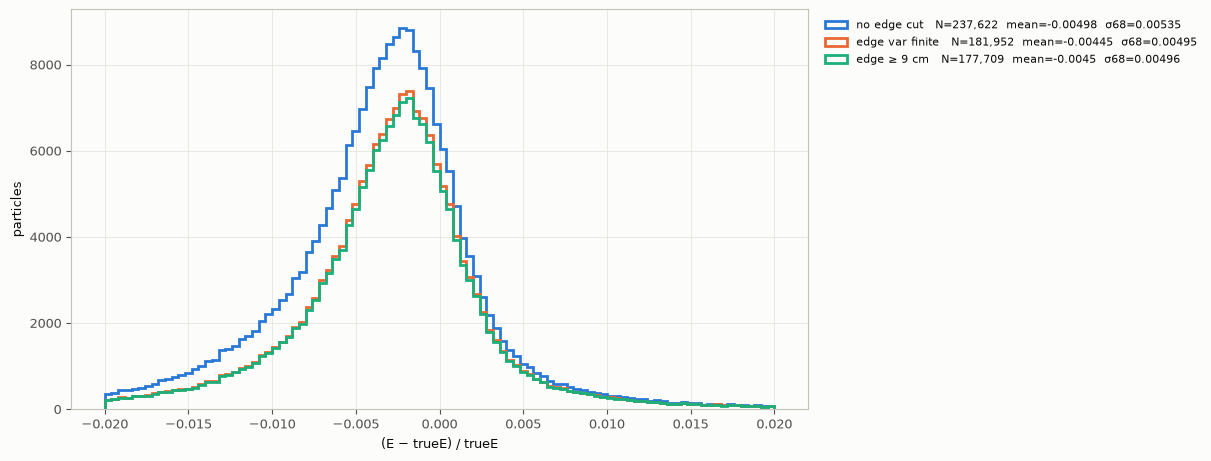

In [85]:
PIDS = [211,-211]            # reco pid(s), e.g. [11], [22], [2112]
LAYER = "first"          # 'pcal', 'ecin', 'ecout' or 'first'
EDGES = [9]   # minimum distance to the edge (cm)
VAR = "E"                # 'E' or 'p', compared with 'true' + VAR
SAME_PID = True          # keep only particles whose matched truth has the reco pid

base = df.pass_loose & vz_window(df, -40, 30) & vt_max(df, 20)  # production minus edge cuts (and chi2pid)
h = df[base & df.pid.isin(PIDS) & (df.truepid != -999)]
if SAME_PID:
    h = h[h.truepid == h.pid]
res = (h[VAR] - h["true" + VAR]) / h["true" + VAR]
edge = calo_edge(h, LAYER)

overlay(res, {"no edge cut": None, "edge var finite": np.isfinite(edge), **{f"edge ≥ {d} cm": edge >= d for d in EDGES}},
        bins=np.linspace(-0.02, 0.02, 101), xlabel=f"({VAR} − true{VAR}) / true{VAR}", density=False)

/u/scigroup/cvmfs/hallb/clas12/sw/almalinux9-gcc11/local/python/3.13.7/lib/python3.13/site-packages/matplotlib/axes/_axes.py:7487: RuntimeWarning: All-NaN slice encountered
  xmin = min(xmin, np.nanmin(xi))
/u/scigroup/cvmfs/hallb/clas12/sw/almalinux9-gcc11/local/python/3.13.7/lib/python3.13/site-packages/matplotlib/axes/_axes.py:7488: RuntimeWarning: All-NaN slice encountered
  xmax = max(xmax, np.nanmax(xi))


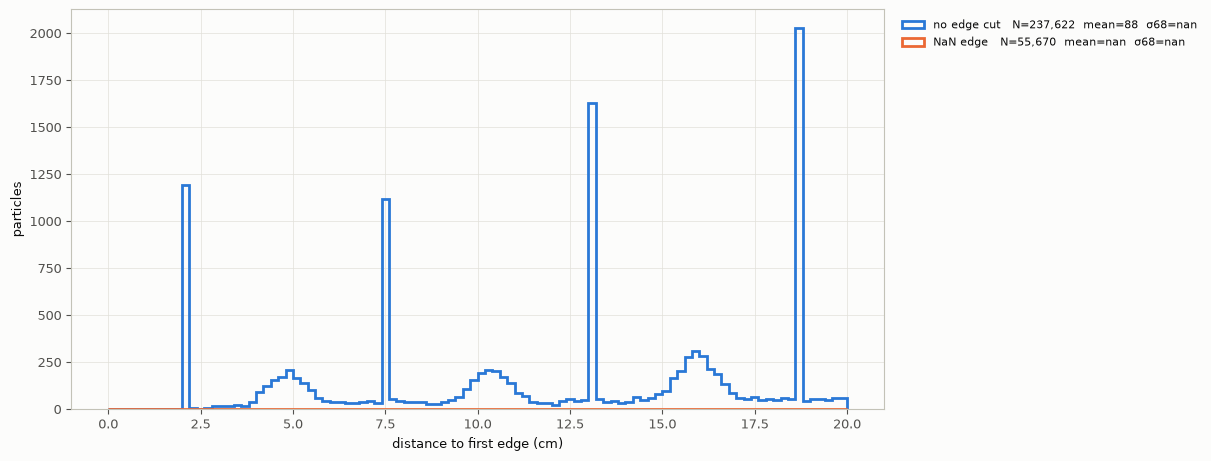

In [ ]:
PIDS = [211,-211]
LAYER = "first"
SAME_PID = True

base = df.pass_loose & vz_window(df, -40, 30) & vt_max(df, 20)  # production minus edge cuts (and chi2pid)
h = df[base & df.pid.isin(PIDS)]
if SAME_PID:
    h = h[h.truepid == h.pid]
edge = calo_edge(h, LAYER)

overlay(edge, {"no edge cut": None, **{f"edge ≥ {d} cm": edge >= d for d in EDGES}},
        bins=np.linspace(0, 20, 101), xlabel=f"distance to {LAYER} edge (cm)", density=False)

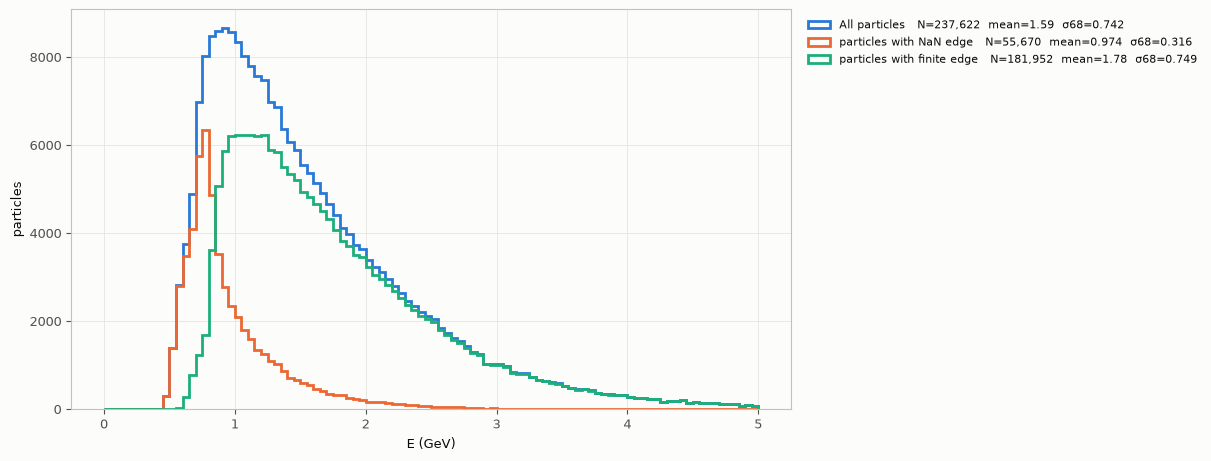

In [87]:
PIDS = [211,-211]
LAYER = "first"
SAME_PID = True

base = df.pass_loose & vz_window(df, -40, 30) & vt_max(df, 20)  # production minus edge cuts (and chi2pid)
h = df[base & df.pid.isin(PIDS)]
if SAME_PID:
    h = h[h.truepid == h.pid]
edges = calo_edge(h, LAYER)


overlay(h.E, {"All particles": None, "particles with NaN edge": ~np.isfinite(edges), "particles with finite edge": np.isfinite(edges)},
        bins=np.linspace(0, 5, 101), xlabel=f"E (GeV)", density=False)

In [77]:
print("# of particles with infinite or NaN edge distances:", np.sum(~np.isfinite(calo_edge(h, LAYER))))

# of particles with infinite or NaN edge distances: 55670


## chi2pid after the v_z / v_T outlier cuts

Particles that pass `pass_loose`, so the production chi2pid cut has not truncated the distribution. The last
selection shows the particles the production outlier cuts remove. Set `VAR` and `BINS` to look at another
variable (e.g. `"vz"`, `"beta"`) under the same selections.

In [131]:
PIDS = [211,-211]

Text(0.5, 1.0, 'vz distribution of [211, -211] particles')

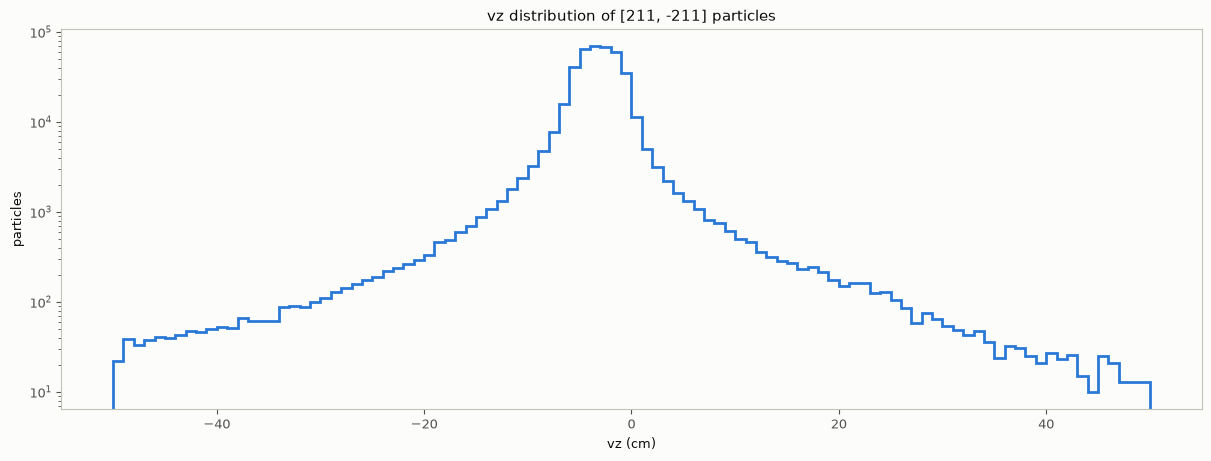

In [132]:
#plot vz of PIDs

VAR = "vz"
fig,ax = plt.subplots(figsize=(12, 4.5), constrained_layout=True)
c = df[df.pass_loose & df.pid.isin(PIDS)]

ax.hist(c[VAR], bins=np.linspace(-50, 50, 101), histtype="step", lw=2, color=COLORS[0])
ax.set_xlabel(f"{VAR} (cm)")
ax.set_ylabel("particles")
ax.set_yscale("log")
ax.set_title(f"{VAR} distribution of {PIDS} particles")


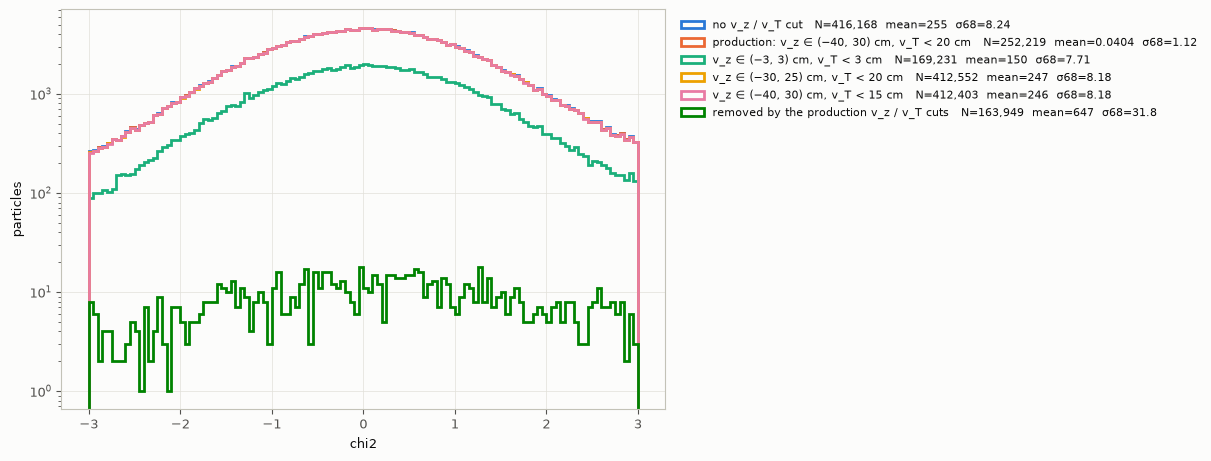

In [134]:

VAR = "chi2"
BINS = np.linspace(-3, 3, 121)

c = df[df.pass_loose & df.pid.isin(PIDS)]
prod = vz_window(c, -40, 30) & vt_max(c, 20) & (c.chi2 > -3) & (c.chi2 < 3)

overlay(c[VAR], {
    "no v_z / v_T cut": None,
    "production: v_z ∈ (−40, 30) cm, v_T < 20 cm": prod,
    "v_z ∈ (−3, 3) cm, v_T < 3 cm": vz_window(c, -3, 3) & vt_max(c, 3),
    "v_z ∈ (−30, 25) cm, v_T < 20 cm": vz_window(c, -30, 25) & vt_max(c, 20),
    "v_z ∈ (−40, 30) cm, v_T < 15 cm": vz_window(c, -40, 30) & vt_max(c, 15),
    "removed by the production v_z / v_T cuts": ~prod,
}, bins=BINS, xlabel=VAR, logy=True)

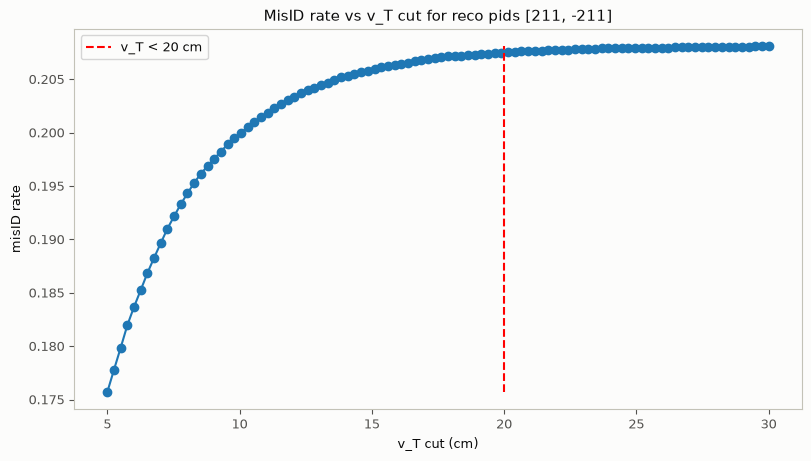

In [135]:
#plot the misID rate per v_z / v_T cut, for the same reco pid(s) and true pid(s)
c = df[df.pass_loose & df.pid.isin(PIDS)]
vT_cuts = np.linspace(5, 30, 100)  # cm
misId_rates = []
num_total = []

for cut in vT_cuts:
    prod = vz_window(c, -40, 30) & vt_max(c, cut) & (c.chi2 > -3) & (c.chi2 < 3)
    misId = (prod & (c.truepid != c.pid)).sum() / (prod).sum()
    misId_rates.append(misId)
    # print(f"v_T < {cut} cm: misID rate = {misId:.3f}")

fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.plot(vT_cuts, misId_rates, marker='o')
ax.vlines(20, ymin=min(misId_rates), ymax=max(misId_rates), color='red', linestyle='--', label='v_T < 20 cm')
ax.set_xlabel("v_T cut (cm)")
ax.set_ylabel("misID rate")
ax.set_title(f"MisID rate vs v_T cut for reco pids {PIDS}")
ax.legend()


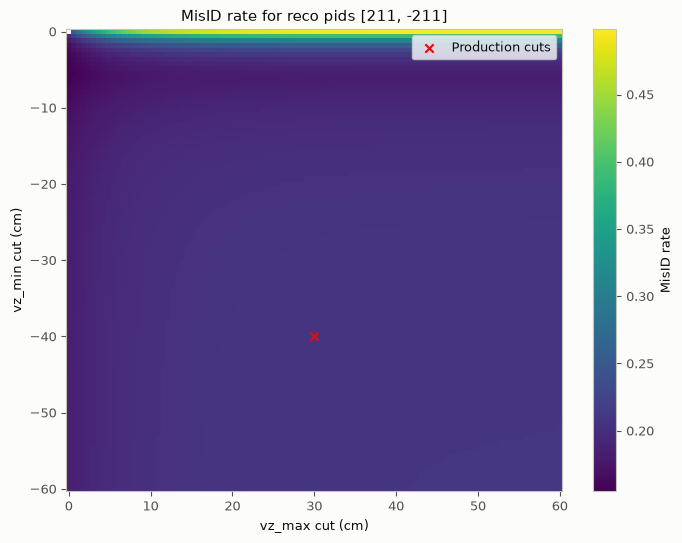

In [136]:
c = df[df.pass_loose & df.pid.isin(PIDS)]

vz_min_cuts = np.linspace(-60, 0, 100)
vz_max_cuts = np.linspace(0, 60, 100)

# Keep the v_T and chi2 cuts fixed
base = vt_max(c, 20) & (c.chi2 > -3) & (c.chi2 < 3)

misId_rates = np.full((len(vz_min_cuts), len(vz_max_cuts)), np.nan)

for i, vz_min in enumerate(vz_min_cuts):
    for j, vz_max in enumerate(vz_max_cuts):
        selected = base & vz_window(c, vz_min, vz_max)

        if selected.sum() > 0:
            misId_rates[i, j] = (
                selected & (c.truepid != c.pid)
            ).sum() / selected.sum()

fig, ax = plt.subplots(figsize=(8, 6))

mesh = ax.pcolormesh(
    vz_max_cuts, vz_min_cuts, misId_rates,
    shading="nearest", cmap="viridis"
)

fig.colorbar(mesh, ax=ax, label="MisID rate")
ax.scatter(30,-40, color='red', marker='x', label='Production cuts')
ax.legend()
ax.set_xlabel("vz_max cut (cm)")
ax.set_ylabel("vz_min cut (cm)")
ax.set_title(f"MisID rate for reco pids {PIDS}")

plt.show()

## Calorimeter hit map

Where the chosen species hits one calorimeter layer, one panel per selection, e.g. to compare the β == 0 photons
with the rest. No pass flag is applied here: the production β outlier cut (0 < β < 2) removes every β == 0
photon, so `pass_prod` hides them (its panel shows what remains). Works for any `PIDS`.

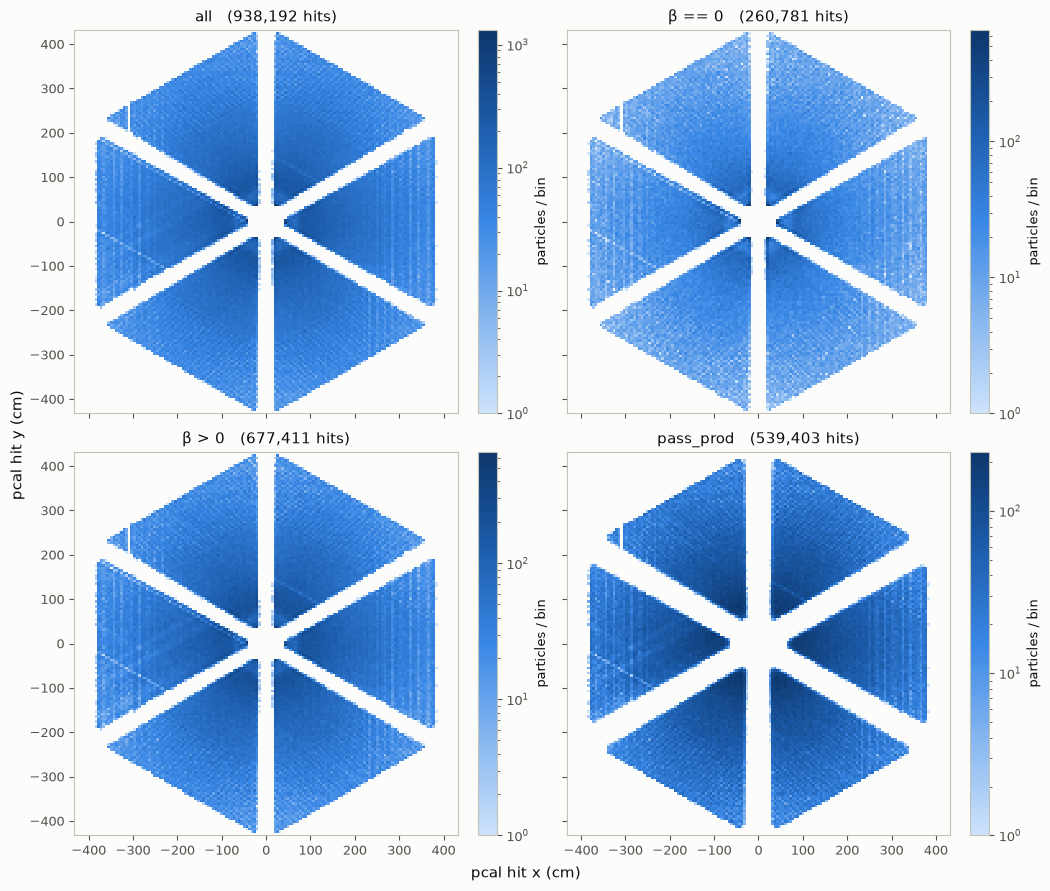

In [48]:
PIDS = [22]       # reco pid(s)
LAYER = "pcal"    # 'pcal', 'ecin', 'ecout' or 'first'

g = df[df.pid.isin(PIDS)]
hit_map(g, {
    "all": None,
    "β == 0": g.beta == 0,
    "β > 0": g.beta > 0,
    "pass_prod": g.pass_prod,
}, layer=LAYER)

In [ ]:
#plot the misID rate per v_z / v_T cut, for the same reco pid(s) and true pid(s)
PIDS = [22]
c = df[df.pass_loose & df.pid.isin(PIDS)]
misId_rates = []
num_total = []

for cut in vT_cuts:
    prod = vz_window(c, -40, 30) & vt_max(c, 20) & (c.chi2 > -3) & (c.chi2 < 3)
    misId = (prod & (c.truepid != c.pid)).sum() / (prod).sum()
    misId_rates.append(misId)
    # print(f"v_T < {cut} cm: misID rate = {misId:.3f}")

fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.plot(vT_cuts, misId_rates, marker='o')
ax.vlines(20, ymin=min(misId_rates), ymax=max(misId_rates), color='red', linestyle='--', label='v_T < 20 cm')
ax.set_xlabel("v_T cut (cm)")
ax.set_ylabel("misID rate")
ax.set_title(f"MisID rate vs v_T cut for reco pids {PIDS}")
ax.legend()


## Photon / electron misID vs. β cut

Matched particles of the chosen reco pid that pass every production cut except the e± / γ β outlier cut
(`pass_nobeta`). For each β selection, one bar per true species gives the fraction of the selection whose closest
truth particle is that species rather than the reco pid. The `TOP` most common wrong species get their own group and
the rest are summed into "other"; the legend gives N and the total misID rate. Particles with no truth match are
left out. `photonBetaCut` (0.9 < β < 1.1) and `leptonBetaCut` (0.8 < β < 1.2) are β cuts already in `CutManager`
but not applied. Set `PIDS = [11]` for electrons.

In [ ]:
PIDS = [22]   # reco pid(s): [22] photons, [11] electrons
TOP = 6       # true species with their own bar group; the rest are summed into 'other'

g = df[df.pass_nobeta & df.pid.isin(PIDS) & (df.truepid != -999)]
misid_bars(g, {
    "no β cut": None,
    "production: 0 < β < 2": beta_window(g, 0, 2),
    "0.8 < β < 1.2 (leptonBetaCut)": beta_window(g, 0.8, 1.2),
    "0.9 < β < 1.1 (photonBetaCut)": beta_window(g, 0.9, 1.1),
    "removed by production: β ≤ 0 or β ≥ 2": ~beta_window(g, 0, 2),
}, top=TOP)